# Tutorial 01: grids and the J table (no spins)

This tutorial reproduces, line by line, the first half of the **BUILD** stage of `stochaxtic/fast_omega.py`:

| Section | Source | Content |
|---|---|---|
| 1 | `__init__`, the "grids" block | the six grids: source-frame mass, redshift, $q$, detector-frame mass, frequency, $x$ |
| 2 | same | the key identity $x_{d+k}=M^{\rm det}_d f_k T_\odot$ |
| 3 | `__init__`, `ln_xJ` | the (coarser) $x$ grid of the J table |
| 4 | `_build_table`, `_table_column` | compute one column $J(x;q)$ by hand and compare with the cached table |

**Method**: write each step yourself first, then compare with the array stored inside `FastOmega`. You have understood a line only when the largest relative difference is 0 (or machine precision).

> Requirements: the default no-spin table cached in `~/.cache/stochaxtic` (otherwise the first run spends a few seconds building it).

In [1]:
import os
for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[k] = "1"

In [2]:
%matplotlib inline
import sys
sys.path.append("../")
FIGDIR = "../../Figures/"

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='ticks', context='notebook', font='serif', 
        font_scale=1.5, palette='deep')
plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amssymb}\usepackage{mathrsfs}\usepackage{bm}", 
    "font.family": "serif",
    'backend': 'pdf',
    # Grid
    "axes.grid": True,
    "grid.alpha": 0.7,
    "grid.linewidth": 0.4,

    # Ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    # Font
    'font.size': 18,
    'legend.fontsize': 18,
})


import jax
jax.config.update("jax_enable_x64", True)          # FastOmega needs float64

import stochaxtic
from stochaxtic.fast_omega import FastOmega, T_SUN
from stochaxtic.constants import Z_MIN_DEFAULT, Z_MAX_DEFAULT

def check(name, mine, ref):
    # largest relative difference between my array and FastOmega's
    mine, ref = np.asarray(mine, float), np.asarray(ref, float)
    assert mine.shape == ref.shape, (name, mine.shape, ref.shape)
    rel = np.max(np.abs(mine - ref) / np.maximum(np.abs(ref), 1e-300))
    print(f"{name:28s} shape {str(ref.shape):16s} max rel diff {rel:.1e}")
    return rel

fo = FastOmega()                                     # default: no spins, IMRPhenomXAS, BBH grid
fo.info

FastOmega: SVD loaded from /home/haowen.zhong/.cache/stochaxtic/svd_IMRPhenomXAS_f596ad348a1a949f.npz
FastOmega: IMRPhenomXAS, spins=None, tides=False: 121 table columns, rank 8; grids lnM 1231, z 444, lnq 121, lnf 1061; setup 0.2 s


{'n_lnM': 1231,
 'n_z': 444,
 'n_q': 121,
 'n_lnf': 1061,
 'n_x': 2734,
 'n_xJ': 1007,
 'n_spin': 1,
 'n_kappa': 1,
 'n_split': 1,
 'split_fractions': (),
 'n_columns': 121,
 'rank': 8,
 'delta': 0.005,
 'q_rule': 'simpson',
 'waveform': 'IMRPhenomXAS',
 'spins': None,
 'tides': False,
 'x_ref': 0.005,
 'm_ref': 20.0,
 'table_seconds': 0.0,
 'cache_file': '/home/haowen.zhong/.cache/stochaxtic/jtable_IMRPhenomXAS_2fe8a23cb39a7106.npy',
 'svd_file': '/home/haowen.zhong/.cache/stochaxtic/svd_IMRPhenomXAS_f596ad348a1a949f.npz',
 'setup_seconds': 0.17719244956970215}

## 1. The six grids

All logarithmic grids of `FastOmega` **share one step** $\delta$ (default 0.005). The whole method rests on this: only with a common step can the convolution and the cross-correlation below be done with one FFT each.

First copy the default arguments of the constructor:

In [4]:
d = 0.005                       # delta
m_tot_range = (1.5, 700.0)      # source-frame total mass [Msun]
z_min, z_max = Z_MIN_DEFAULT, Z_MAX_DEFAULT
q_min, n_q = 0.01, 121
freqs = np.arange(5.0, 1001.0, 1.0)
print(z_min, z_max)

0.2 10.0


### 1a. Source-frame total mass $\ell_i=\ln M_{\rm src}$

Start at $\ln M_{\min}$ and step by $\delta$ until $M_{\max}$ is covered (with `ceil`, so the last point may lie slightly above 700).

In [5]:
# We need np.ceil(...) to ensure that l_src[-1] >= m_max
# For example, d=0.3, m_min = 1, m_max=5, we need ceil(4/0.3)=13 instead of floor(4/0.3)=12
l_src = np.log(m_tot_range[0]) + d * np.arange(int(np.ceil(np.log(m_tot_range[1] / m_tot_range[0]) / d)) + 1)
check("l_src", l_src, fo.l_src)
print("n_l =", len(l_src), ", M range:", np.exp(l_src[[0, -1]]))

l_src                        shape (1231,)          max rel diff 0.0e+00
n_l = 1231 , M range: [  1.5        703.07608017]


### 1b. Redshift $\xi_j=\ln(1+z_j)$ and trapezoid weights

In the source this array is `self.xi` ($\xi=\ln(1+z)$), named so to keep it apart from $x=MfT_\odot$.

Why $\ln(1+z)$ rather than $z$? Redshift acts on mass as $M_{\rm det}=(1+z)M_{\rm src}$, i.e. $\ln M_{\rm det}=\ln M_{\rm src}+\xi$. If $\xi$ and $\ln M$ share one step, redshifting becomes "a shift by an integer number of cells along the mass axis", and the redshift integral becomes a discrete convolution.

The weights `wxi` are trapezoid weights in $\xi$: half cells at both ends, and **the last cell is treated separately**, because $\xi_{\max}=\ln 11$ in general does not fall on a grid point ("close the last partial interval").

In [6]:
xi0, xi1 = np.log1p(z_min), np.log1p(z_max)
n_z = int(np.floor((xi1 - xi0) / d)) + 1
xi = xi0 + d * np.arange(n_z)
wxi = np.full(n_z, d)
wxi[0] *= 0.5
wxi[-1] = 0.5 * d + (xi1 - xi[-1])       # half cell + the leftover piece up to xi1
z = np.expm1(xi)

check("xi = ln(1+z)", xi, fo.xi)
check("z", z, fo.z)
print("n_z =", n_z, "  sum of weights =", wxi.sum(), " vs  xi1 - xi0 =", xi1 - xi0)

xi = ln(1+z)                 shape (444,)           max rel diff 0.0e+00
z                            shape (444,)           max rel diff 0.0e+00
n_z = 444   sum of weights = 2.2155737160044158  vs  xi1 - xi0 = 2.215573716004416


**Exercise**: the weights must sum exactly to the length of the interval, $\xi_1-\xi_0$ (printed above). Check also that they integrate a smooth function accurately, e.g. $\int_{\xi_0}^{\xi_1}e^{\xi}\,d\xi=e^{\xi_1}-e^{\xi_0}=z_{\max}-z_{\min}$:

In [7]:
print(np.sum(wxi * np.exp(xi)), "vs exact", z_max - z_min)

9.800018593881246 vs exact 9.8


(The error is $O(\delta^2)$, plus the error of the incomplete last interval, which is integrated as a rectangle of width $<\delta$; for $\delta=0.005$ this is more than enough.)

### 1c. Mass ratio $\ln q_s$ and Simpson weights

The $q$ direction does **not** have to share the step of the other grids ($q$ takes no part in the convolutions), so it uses uniform $\ln q$ nodes with Simpson's rule. The number of nodes must be odd (an even number is increased by 1). The Simpson weights are $\tfrac{h}{3}(1,4,2,4,\dots,2,4,1)$.

In [8]:
lq = np.linspace(np.log(q_min), 0.0, n_q)
hq = lq[1] - lq[0]
wq = np.full(n_q, 2.0)
wq[1::2] = 4.0
wq[[0, -1]] = 1.0
wq *= hq / 3.0
check("lq", lq, fo.lq)
check("wq (Simpson)", wq, fo.wq)
print("sum wq =", wq.sum(), " = -ln q_min =", -np.log(q_min))

lq                           shape (121,)           max rel diff 0.0e+00
wq (Simpson)                 shape (121,)           max rel diff 0.0e+00
sum wq = 4.605170185988108  = -ln q_min = 4.605170185988091


### 1d. Detector-frame mass $\ell^{\rm det}_d$

$\ell^{\rm det}=\ell+\xi$, with $n_\ell$ points in $\ell$ and $n_z$ points in $\xi$ on the same step, so every possible sum falls on a grid of $n_d=n_\ell+n_z-1$ points (like the sum of two dice):

In [9]:
n_l = len(l_src)
n_d = n_l + n_z - 1
l_det = l_src[0] + xi[0] + d * np.arange(n_d)
check("l_det", l_det, fo.l_det)

# index arithmetic: l_src[i] + xi[j] sits exactly on l_det[i + j]
i, j = 400, 123
print(l_src[i] + xi[j], l_det[i + j])

l_det                        shape (1674,)          max rel diff 0.0e+00
3.2027866649021193 3.2027866649021193


### 1e. Frequency $\ln f_k$ and the $x$ grid $\ln x_m$

The internal frequency grid starts at the lowest user frequency, again with step $\delta$ (the result is interpolated back to the user's `freqs` at the very end, see chapter 03).

The $x$ grid must cover every possible $x=M_{\rm det}fT_\odot$, i.e. $\ln x=\ln T_\odot+\ell^{\rm det}+\ln f$. Again a "sum of two grids with equal steps", with $n_x=n_d+n_f-1$ points.

In [10]:
lnf0 = np.log(freqs.min())
n_f = int(np.ceil(np.log(freqs.max() / freqs.min()) / d)) + 1
lnf = lnf0 + d * np.arange(n_f)
n_x = n_d + n_f - 1
ln_x = np.log(T_SUN) + l_det[0] + lnf0 + d * np.arange(n_x)
check("lnf", lnf, fo.lnf)
check("ln_x", ln_x, fo.ln_x)
print(f"n_f = {n_f}, n_x = {n_x};  x from {np.exp(ln_x[0]):.2e} to {np.exp(ln_x[-1]):.2e}")

lnf                          shape (1061,)          max rel diff 0.0e+00
ln_x                         shape (2734,)          max rel diff 0.0e+00
n_f = 1061, n_x = 2734;  x from 4.43e-05 to 3.81e+01


## 2. The pivot of the method: $x_{d+k}=M^{\rm det}_d f_k T_\odot$

By construction $\ln x_m=\ln T_\odot+\ell^{\rm det}_0+\ln f_0+m\delta$, while $\ell^{\rm det}_d+\ln f_k=\ell^{\rm det}_0+\ln f_0+(d+k)\delta$. Hence

$$x_{d+k}=M^{\rm det}_d\,f_k\,T_\odot\qquad\text{(exact, no interpolation)}.$$

So $\Omega(f_k)\propto\sum_d K_d\,J(x_{d+k})$ is a **cross-correlation** (the index is $d+k$), which a single FFT computes for all $k$ at once. Check a few random $(d,k)$:

In [11]:
rng = np.random.default_rng(0)
for _ in range(5):
    dd, kk = rng.integers(n_d), rng.integers(n_f)
    lhs = ln_x[dd + kk]
    rhs = np.log(T_SUN) + l_det[dd] + lnf[kk]
    print(f"d={dd:5d} k={kk:5d}   ln x[d+k] - ln(M_det f T) = {lhs - rhs:+.1e}")

d= 1423 k=  675   ln x[d+k] - ln(M_det f T) = -8.9e-16
d=  855 k=  286   ln x[d+k] - ln(M_det f T) = -8.9e-16
d=  515 k=   43   ln x[d+k] - ln(M_det f T) = -1.8e-15
d=  125 k=   17   ln x[d+k] - ln(M_det f T) = -1.8e-15
d=  293 k=  862   ln x[d+k] - ln(M_det f T) = -2.7e-15


## 3. The table's own $x$ grid `ln_xJ`

The J table is not built on the $n_x=2734$ points directly but on a **coarser** grid (step `table_step` $\times\delta=2\delta$), and then interpolated back to $\ln x_m$ with cubic splines (chapter 02). The reason: $J$ is smooth, so a coarse grid plus splines is accurate enough, and the cost of building the table is proportional to the number of points.

Two details:
- the upper end is $\min(\ln x_{\max},0)$: at $x=MfT_\odot=1$ every waveform has long ended (the ringdown sits at $x\sim0.1$), and the table is zero above;
- below, the grid starts exactly two cells under $\ln x_{\min}$ (`- 2*dJ`), so the first fine point stays clear of the spline's end condition; above, `np.arange` excludes its stop `lx_hi + 2*dJ`, so the margin over $\ln x=0$ is one to two cells (1.6 here). That is enough: $J$ is already zero there (below $10^{-12}$ of its peak from $x\approx0.13$), and the fine grid above the last live node is multiplied by a zero row scale, so the spline is never used there.

In [12]:
table_step = 2
dJ = table_step * d
lx_hi = min(ln_x[-1], 0.0)
ln_xJ = np.arange(ln_x[0] - 2 * dJ, lx_hi + 2 * dJ, dJ)
check("ln_xJ", ln_xJ, fo.ln_xJ)
print("n_xJ =", len(ln_xJ), " (vs n_x =", n_x, ")")

ln_xJ                        shape (1007,)          max rel diff 0.0e+00
n_xJ = 1007  (vs n_x = 2734 )


## 4. One column $J(x;q_s)$ by hand

**Scale invariance**: $I(f;M,q)=M^4J(MfT_\odot;q)$. So the intensity at **one** reference mass $m_{\rm ref}$ (default 20 $M_\odot$) gives the whole column of $J$:

$$J(x_t;q_s)=\frac{I\big(f_t=x_t/(m_{\rm ref}T_\odot);\ m_{\rm ref},q_s\big)}{m_{\rm ref}^4}.$$

This is exactly what `_table_column` does. Details (compare with the source):
- only the points with $x<1$ (`live`) are computed; the rest are set to 0;
- $q$ is capped at $1-10^{-6}$: XP/XPHM have a jump exactly at $m_1=m_2$, and taking the limit avoids it;
- without spins the spin samples have $a=0$ (`_draw_spins` sets `cos t = 1`, but $a=0$, so the spin vectors vanish);
- `OrientationAverager` averages exactly over the observer directions (XAS has only the 22 mode, for which the face-on rule is exact);
- `f_ref` is $x_{\rm ref}/(m_{\rm ref}T_\odot)$: irrelevant without spins, but it keeps the convention consistent.

`fo.table()` returns the cached table as a read-only memory map of shape `(n_q, n_kappa, n_split, n_spin, n_xJ)`. `n_split` is 1 except for the NRTidalv3 tables (chapter 05), so `[:, :, 0]` drops that axis. The file name is in `fo.info["cache_file"]`.

In [13]:
from stochaxtic.orientation import OrientationAverager

J_cached = fo.table()[:, :, 0]       # split axis dropped: (n_q, n_kappa, n_spin, n_xJ)
print("cached table:", J_cached.shape)

m_ref, x_ref = fo.info["m_ref"], fo.info["x_ref"]
avg = OrientationAverager("IMRPhenomXAS")
xJ = np.exp(ln_xJ)
live = xJ < 1.0

def my_column(s):
    q = min(np.exp(lq[s]), 1.0 - 1e-6)
    m1, m2 = m_ref / (1 + q), m_ref * q / (1 + q)
    col = np.zeros(len(xJ))
    col[live] = avg(xJ[live] / (m_ref * T_SUN), m1, m2, (0, 0, 0), (0, 0, 0),
                    f_ref=x_ref / (m_ref * T_SUN)) / m_ref ** 4
    return col

for s in (0, 60, 120):                                  # q = 0.01, 0.1, 1
    check(f"J column s={s} (q={np.exp(lq[s]):.3f})", my_column(s), J_cached[s, 0, 0])

cached table: (121, 1, 1, 1007)
J column s=0 (q=0.010)       shape (1007,)          max rel diff 0.0e+00
J column s=60 (q=0.100)      shape (1007,)          max rel diff 0.0e+00
J column s=120 (q=1.000)     shape (1007,)          max rel diff 0.0e+00


/home/haowen.zhong/StochAXtic/StochAXtic/tutorials/../stochaxtic/orientation.py:103: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


### A look at the table

Plot the columns for a few values of $q$. The vertical axis spans more than twenty decades: the $x^{-7/3}$ inspiral power law at low $x$, the merger at $x\sim0.01$–$0.1$, and the exponentially decaying ringdown above. This huge dynamic range is what the row normalisation $\varsigma_t$ and the preconditioning $x^{7/3}$ of chapter 02 deal with.

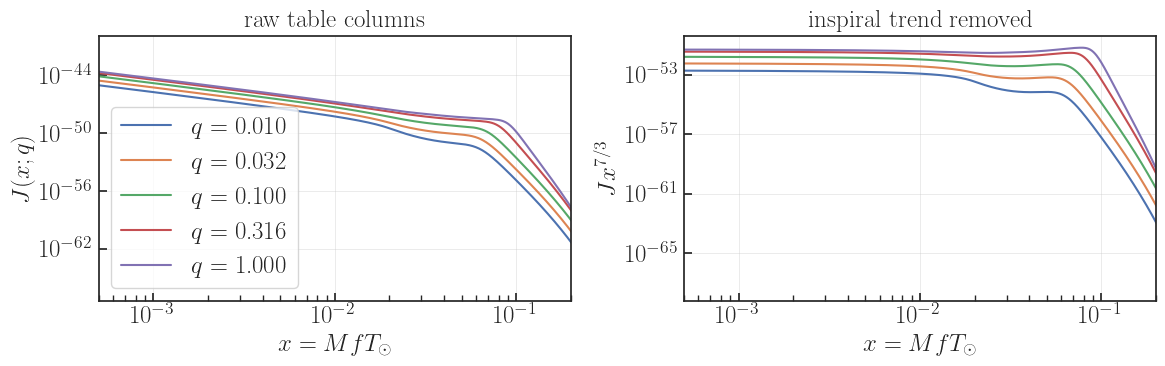

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s in (0, 30, 60, 90, 120):
    J = J_cached[s, 0, 0]
    ok = J > 0
    ax[0].loglog(xJ[ok], J[ok], label=fr"$q$ = {np.exp(lq[s]):.3f}")
    ax[1].loglog(xJ[ok], J[ok] * xJ[ok] ** (7 / 3), label=f"q = {np.exp(lq[s]):.3f}")
ax[0].set(xlabel=r"$x = M f T_\odot$", ylabel=r"$J(x; q)$", title="raw table columns")
ax[1].set(xlabel=r"$x = M f T_\odot$", ylabel=r"$J x^{7/3}$", title="inspiral trend removed")
ax[0].legend()
ax[0].set_xlim(5e-4, 2e-1)
ax[1].set_xlim(5e-4, 2e-1)
plt.tight_layout()

## 5. Exercise: check the scale invariance

Recompute the same column with $m_{\rm ref}=60\,M_\odot$. You should get the **same** $J(x)$ (to machine precision): the table does not depend on the choice of $m_{\rm ref}$, which only sets the range of physical frequencies at which LAL is actually called.

In [15]:
s = 60
q = np.exp(lq[s]); m_alt = 60.0
m1, m2 = m_alt / (1 + q), m_alt * q / (1 + q)
col_alt = np.zeros(len(xJ))
col_alt[live] = avg(xJ[live] / (m_alt * T_SUN), m1, m2, (0, 0, 0), (0, 0, 0),
                    f_ref=x_ref / (m_alt * T_SUN)) / m_alt ** 4
ok = J_cached[s, 0, 0] > 1e-15 * J_cached[s, 0, 0].max()
print("max rel diff (m_ref = 60 vs 20):", np.max(np.abs(col_alt[ok] / J_cached[s, 0, 0][ok] - 1)))

max rel diff (m_ref = 60 vs 20): 2.1760371282653068e-13


## Summary

| Array | Meaning | Shape (default) |
|---|---|---|
| `l_src` | source-frame $\ln M$ | 1231 |
| `xi` / `z` | $\xi=\ln(1+z)$ / $z$ | 444 |
| `lq`, `wq` | $\ln q$ nodes, Simpson weights | 121 |
| `l_det` | detector-frame $\ln M$ | 1674 |
| `lnf` | internal uniform $\ln f$ | 1061 |
| `ln_x` | fine $x$ grid | 2734 |
| `ln_xJ` | coarse table grid | 1007 |
| `fo.table()[:, :, 0]` | cached $J(x_t;q_s)$ | (121, 1, 1, 1007) |

**Next chapter (02)**: row-normalise this $1007\times121$ table, weight its columns and take the SVD to split it into a basis $B_{tr}$ and coefficients $C_{rs}$; then interpolate the basis to the fine grid, multiply by $x^{7/3}$ and FFT. This reproduces `fo._B`, `fo._C` and `fo._FJ` line by line.